# DFA and Factor Investing

## HBS Case
### *Dimensional Fund Advisors, 2002* [HBS 9-203-026]

Pages 1-5 of the case are required. Pages 6-11 discuss trading (especially adverse selection) and taxes. These sections are useful for market background, but are optional.

# 1. READING - DFA's Strategy

#### 1. Investment philosophy.

* In 100 words or less, describe DFA's belief about how to find premium in the market.

* To what degree does their strategy rely on individual equity analysis? Macroeconomic fundamentals? Efficient markets?

* Are DFA's funds active or passive?

* What do DFA and others mean by a "value" stock? And a "growth" stock?

#### 2. Challenges for DFA's view.

* What challenge did DFA's model see in the 1980's?

* And in the 1990's?

#### 3. The market.

* Exhibit 3 has data regarding a universe of 5,020 firms. How many are considered ``large cap"? What percent of the market value do they account for?

* Exhibit 6 shows that the U.S. value factor (HML) has underperformed the broader U.S. equity market in 1926-2001, including every subsample except 1963-1981. So why should an investor be interested in this value factor?

#### 1. Investment philosophy

1. DFA believes markets are efficient, so no one can consistently pick winning stocks. Premium comes from bearing systematic risks that academic research has identified, chiefly the size effect (small caps) and the value effect (high book-to-market), captured through broadly diversified, low-cost, low-turnover portfolios. DFA adds further value through skilled trading, buying illiquid blocks at a discount so its transaction costs are often negative.

2. DFA does essentially no individual equity analysis; it does no fundamental valuation and screens trades only to avoid adverse selection (pending news, insider sales, untrustworthy sellers). It doesn't use macroeconomic forecasts or market timing either. Its strategy rests heavily on efficient markets, and it interprets the size and value premia as compensation for risk rather than mispricing.

3. They are essentially passive, since DFA holds broad, value-weighted portfolios tracking size and value asset classes without stock picking. They aren't pure index funds, though: the factor tilts, the opportunistic block trading that lets weights drift from the index, and the tax management are "active" in implementation, which is why DFA's fees sit between index and active funds.

4. A value stock has a high book-to-market ratio, meaning a low price relative to book equity, and is often a distressed firm with weak recent returns and profitability. A growth stock has a low book-to-market ratio, like the late-1990s tech firms with high market caps and few assets in place. DFA preferred the "growth" label over "glamour" because "glamour" implies overhyped, mispriced stocks, which conflicts with its efficient-markets view.

#### 2. Challenges for DFA's view

1. Right after DFA launched its small-cap fund in 1982, small stocks badly lagged large stocks and the S&P 500 (SMB averaged -0.9% over 1982-93). Critics said DFA either bought in at the peak or that the size effect disappeared once it was published and traded on.

2. History repeated with value: value stocks did fine, but growth stocks, especially large-cap tech, massively outperformed, so DFA looked like it was "missing the boat." This raised the same worry that the value premium had been arbitraged away, at least until value's huge rebound in 2000-01.

#### 3. The market

1. Only 207 of the 5,020 firms (about 4%) are large cap, yet they account for roughly 70% of total market value.

2. HML is a zero-cost long-short portfolio, so the right comparison is risk-adjusted, not raw returns. With much lower volatility (12.5% vs. 19.1%), its Sharpe ratio of about 0.38 is close to the market's 0.41, and globally HML's Sharpe (about 0.63) beats the market's (about 0.51). More importantly, HML is an addition to the market rather than a replacement: it often pays off when the market doesn't (1963-81, and over 80% in 2000-01 while the market fell), so adding it to a market portfolio improves diversification and overall Sharpe.

In [40]:
from pathlib import Path
import seaborn as sns
import statsmodels.api as sm
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter
from IPython.display import display


# 2. The Factors

DFA believes certain stocks have higher expected excess returns. In addition to the overall market equity premium, DFA believes that there is a premium attached to a **size** and **value** factor.

### Data

Use `data/dfa_analysis_data.xlsx` from the [course Box folder](https://uchicago.app.box.com/s/w3oqz9iy0kav3n3l4pa04p6etndo2ez2). Monthly data covers July 1926 through August 2026. Returns are stored as decimals.

- **Factors:** Use all three columns, `Mkt-RF`, `SMB`, and `HML`, in the `factors` sheet for Section 2. They are already excess returns; do not subtract `RF` from them.
- **Risk-free return:** `RF` is the monthly risk-free return. Use it to convert the portfolios' total returns to excess returns in Section 3.
- **Portfolios:** The `portfolios (total returns)` sheet contains 25 value-weighted portfolios sorted by size and book-to-market.

Source: [Ken French Data Library](https://mba.tuck.dartmouth.edu/pages/faculty/ken.french/data_library.html).

In [24]:
raw = pd.read_excel('FINM Portfolio/dfa_analysis_data.xlsx', sheet_name='factors', header=0, index_col=0)
raw.index = pd.to_datetime(raw.index)
raw = raw.sort_index()

factors = raw[["Mkt-RF", "SMB", "HML"]].copy()
factors = factors.loc["1926-07":"2026-08"]


DFA_rets = pd.read_excel('FINM Portfolio/dfa_analysis_data.xlsx', sheet_name='portfolios (total returns)', header=0, index_col=0)


### 1. The Factors

Calculate the univariate performance statistics for each of the three factors: 

* annualized mean
* annualized volatility
* annualized Sharpe ratio
* monthly VaR(.05), reported as the fifth percentile of returns

Report these for the following three subsamples:

* July 1926 - December 1980
* January 1981 - December 2001
* January 2002 - August 2026



In [26]:
def performance_stats(returns): 
    annual_mean = returns.mean() * 12
    annual_vol = returns.std(ddof=1) * np.sqrt(12)

    return pd.DataFrame({
        "Annualized mean" : annual_mean,
        "Annualized volatility" : annual_vol,
        "Annualized Sharpe" : annual_mean / annual_vol,
        "Monthly VaR (5%)" : returns.quantile(0.05),
    })

last_month = factors.index.max().strftime("%Y-%m")

samples = {
    "1926-07 to 1980-12": factors.loc["1926-07":"1980-12"],
    "1981-01 to 2001-12": factors.loc["1981-01":"2001-12"],
    f"2002-01 to {last_month}": factors.loc["2002-01":"2026-08"],
}

stats = pd.concat(
    {label: performance_stats(data) for label, data in samples.items()},
    names=["Period", "Factor"]
)

formats = {
    "Annualized mean": "{:.2%}",
    "Annualized volatility": "{:.2%}",
    "Annualized Sharpe": "{:.3f}",
    "Monthly VaR (5%)": "{:.2%}",
}

display(stats.style.format(formats))


### 2. 

Based on the factor statistics above, answer the following.

- Does each factor have a premium (positive expected excess return) in each subsample?

- Does the premium to the size factor get smaller after 1980?

- Does the premium to the value factor get smaller during the 1990's?

- How have the factors performed since the time of the case, (January 2002 - August 2026)?



In [27]:
decade_stats = pd.concat(
    {
        "1980–1989": performance_stats(factors.loc["1980":"1989"]),
        "1990–1999": performance_stats(factors.loc["1990":"1999"]),
    },
    names=["Decade", "Factor"]
)

display(decade_stats.style.format(formats))

- Here market and value have a positive sample mean in all three. Size has a negitive sample mean during 1981-2001. A positive historical average estimates a preimum but does not give us that the true expected return is positive. 
- The size premium does shrink after 1980. Its annualized mean falls from 3.39% to -0.2% and has a modest performance after 2001. 
- We see HML (premium to value) annualized mean fall from 5.95% in the 1980s to 0.052% in the 1990s. So it did weaken during the 1990s. 
- In the time of the case through August 2026 the market has delivered the strongest average return and Sharpe ratio. Size has offered a small average premium, and value’s average premium has been close to zero.

### 3.

The factors are constructed in such a way as to reduce correlation between them.

* Report the correlation matrix across the three factors. 

* Does the construction method succeed in keeping correlations small? 

* Does it achieve this in each subsample?



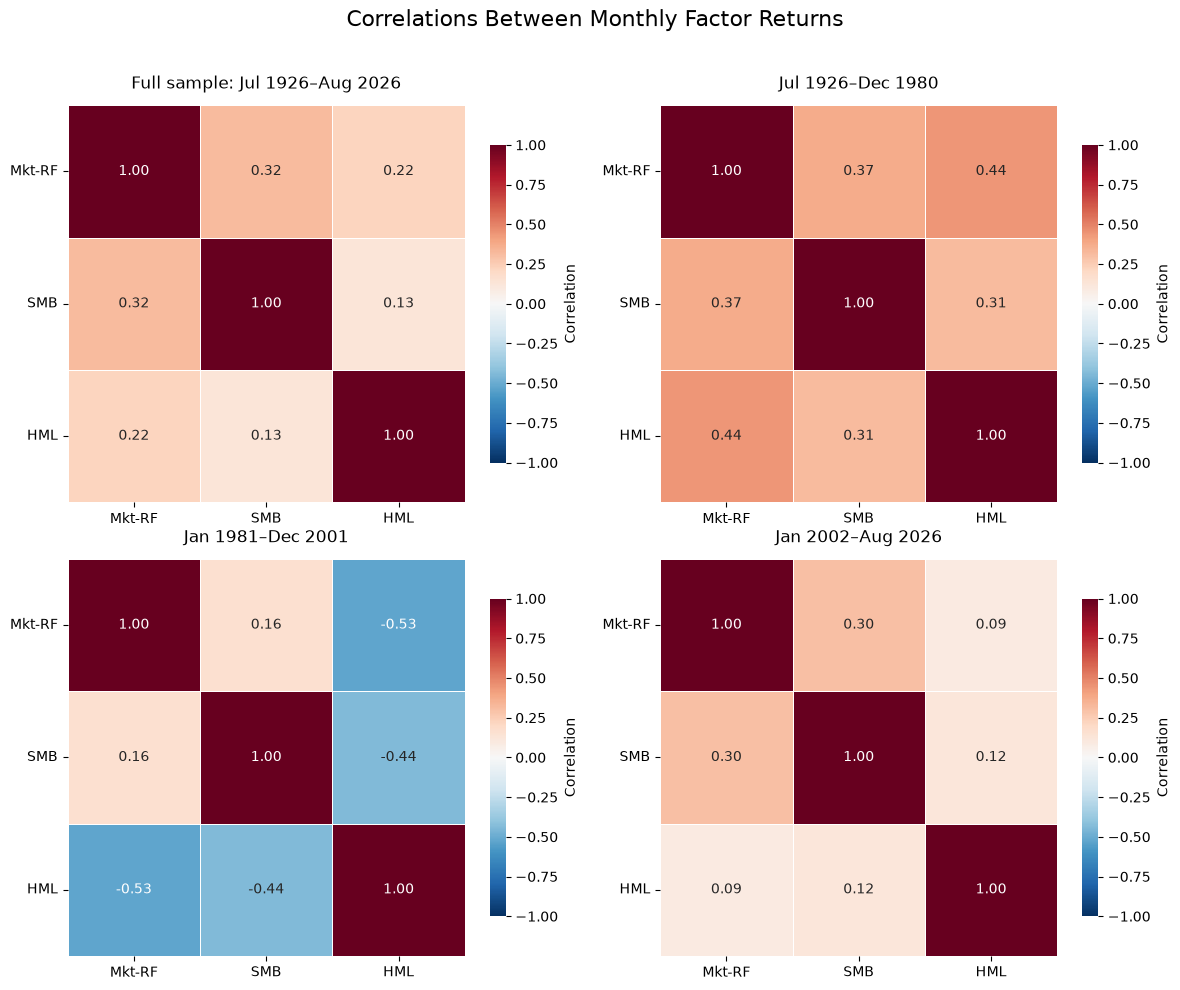

In [31]:
periods = {
    "Full sample: Jul 1926–Aug 2026": factors,
    "Jul 1926–Dec 1980": factors.loc["1926-07":"1980-12"],
    "Jan 1981–Dec 2001": factors.loc["1981-01":"2001-12"],
    "Jan 2002–Aug 2026": factors.loc["2002-01":"2026-08"],
}

fig, axes = plt.subplots(2, 2, figsize=(12, 10))

for ax, (title, data) in zip(axes.flat, periods.items()):
    sns.heatmap(
        data.corr(),
        annot=True,
        fmt=".2f",
        cmap="RdBu_r",
        vmin=-1,
        vmax=1,
        center=0,
        square=True,
        linewidths=0.5,
        cbar_kws={"label": "Correlation", "shrink": 0.8},
        ax=ax,
    )
    ax.set_title(title, pad=12)
    ax.tick_params(axis="both", rotation=0)

fig.suptitle("Correlations Between Monthly Factor Returns", fontsize=16)
plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.show()

The factors have low to moderate correlations overall, but they are not consistently close to uncorrelated in every subsample. For example in 1981–2001, HML’s correlation with the market is about −0.53 which is meaningful diversification but substantial co-movement in opposite directions. 

### 4. 

* Plot the cumulative returns of the three factors. 

* Create plots for the 1981-2001 subsample as well as the January 2002 - August 2026 subsample.



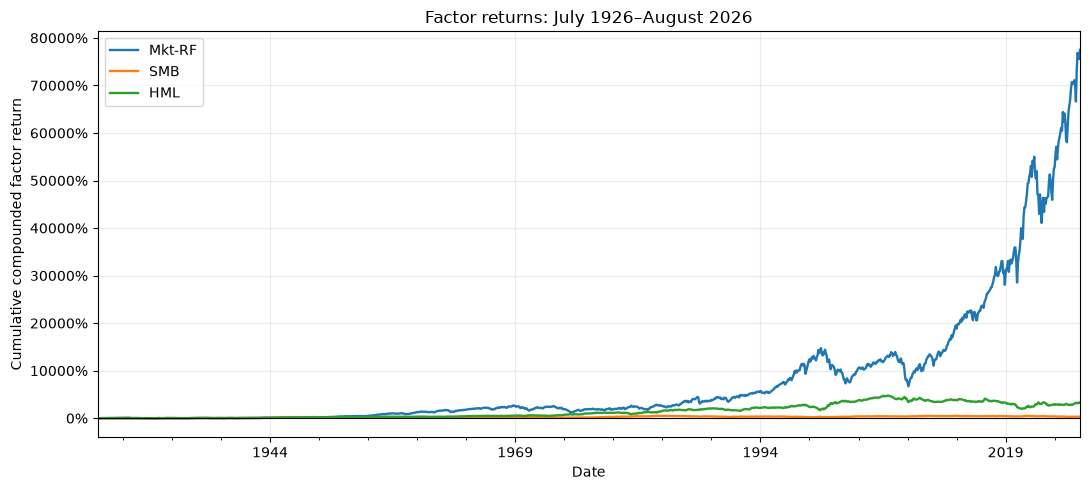

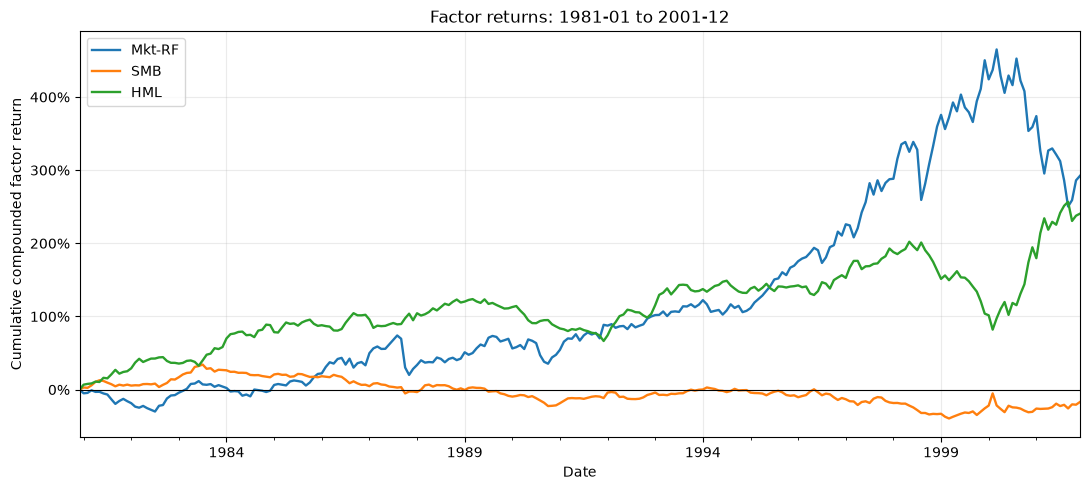

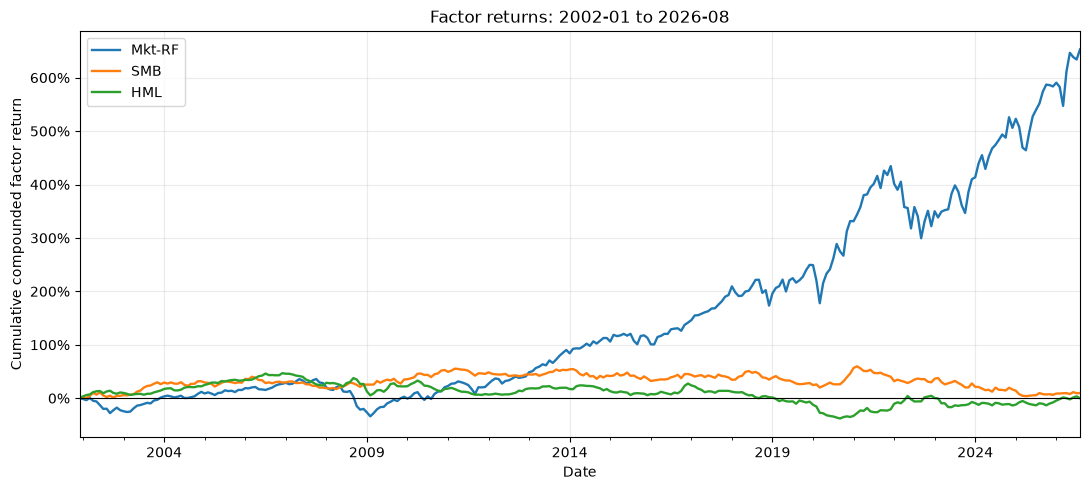

In [32]:
def plot_cumulative(returns, title):
    cumulative = (1 + returns).cumprod() - 1

    # Add a zero starting point before the first month's return.
    start = returns.index[0] - pd.offsets.MonthEnd(1)
    initial = pd.DataFrame(
        0.0,
        index=[start],
        columns=returns.columns
    )
    cumulative = pd.concat([initial, cumulative])

    ax = cumulative.plot(figsize=(11, 5), linewidth=1.7)
    ax.axhline(0, color="black", linewidth=0.8)
    ax.set_title(title)
    ax.set_xlabel("Date")
    ax.set_ylabel("Cumulative compounded factor return")
    ax.yaxis.set_major_formatter(PercentFormatter(1))
    ax.grid(alpha=0.25)
    plt.tight_layout()
    plt.show()


plot_cumulative(
    factors,
    f"Factor returns: July 1926–{factors.index.max():%B %Y}"
)

for label, data in list(samples.items())[1:]:
    plot_cumulative(data, f"Factor returns: {label}")

### 5.

* Does it appear that all three factors were valuable in 1981-2001? 
* And post-2001? 

Would you advise DFA to continue emphasizing all three factors?

In [33]:
cumulative_returns = pd.DataFrame({
    "1981–2001": (
        (1 + factors.loc["1981-01":"2001-12"]).prod() - 1
    ),
    "2002–Aug 2026": (
        (1 + factors.loc["2002-01":"2026-08"]).prod() - 1
    ),
})

display(
    cumulative_returns.style
    .format("{:,.2%}")
    .set_caption("Cumulative Compounded Factor Returns")
)

,1981–2001,2002–Aug 2026
Mkt-RF,292.27%,652.84%
SMB,-16.88%,9.62%
HML,240.56%,-0.25%


For 1981 to 2001 the market and value both look very attractive the have large positive means and value has a higher Sharpe ratio than the market plus a negative correlation with it. Size has weak standalone evidence, with a negative average and cumulative return. Its correlations mean it could still affect a combined portfolio, so standalone performance alone does not prove it is useless.

For post-2001, the market dominates. Size’s realized reward is modest, while value’s average return is nearly zero and its compounded index declines.

For DFA they should retain the market as the core exposure while reassessing how strongly to emphasize size and value. Their historical diversification and earlier premia support considering them, but the later sample gives weak support for expecting large rewards from either.

# 3. CAPM

In [36]:
factor_data = raw.copy()
factor_data.index = pd.to_datetime(factor_data.index)
factor_data = factor_data.sort_index().loc["1981-01":"2026-08"]

portfolio_returns = DFA_rets.copy()
portfolio_returns.index = pd.to_datetime(portfolio_returns.index)
portfolio_returns = portfolio_returns.sort_index().loc["1981-01":"2026-08"]

excess_returns = portfolio_returns.sub(factor_data["RF"], axis=0)

market = factor_data["Mkt-RF"]


DFA believes that premia in stocks and stock portfolios are related to the three factors. 

Let's test `25` equity portfolios that span a wide range of size and value measures.

#### Footnote
For more on the portfolio construction, see the description at Ken French's data library. 
https://mba.tuck.dartmouth.edu/pages/faculty/ken.french/Data_Library/tw_5_ports.html

#### Portfolios
Monthly **total** return data on `25` equity portfolios sorted by their size-value characteristics. Denote these as $\vec{r}^{i}$, for $n=1, \ldots, 25$.
- Note that while the factors were given as excess returns, the portfolios are total returns.
- For this entire problem, focus on the January 1981 - August 2026 subsample.

### 1. Summary Statistics. 

For each portfolio, 
- Use the `RF` column in the `factors` sheet to convert these total returns to excess returns.
- Calculate the (annualized) univariate statistics from `2.1`; keep VaR at the monthly frequency.

In [37]:
portfolio_stats = performance_stats(excess_returns)

display(portfolio_stats.style.format(formats))

,Annualized mean,Annualized volatility,Annualized Sharpe,Monthly VaR (5%)
SMALL LoBM,1.63%,27.11%,0.060,-12.26%
ME1 BM2,9.28%,23.43%,0.396,-9.57%
ME1 BM3,9.62%,20.03%,0.480,-8.44%
ME1 BM4,11.68%,19.26%,0.607,-7.72%
SMALL HiBM,13.05%,20.67%,0.631,-8.72%
ME2 BM1,6.61%,24.37%,0.271,-10.25%
ME2 BM2,10.51%,20.49%,0.513,-8.35%
ME2 BM3,11.10%,18.64%,0.595,-7.90%
ME2 BM4,10.97%,18.10%,0.606,-7.50%
ME2 BM5,11.61%,21.24%,0.547,-9.24%


### 2. CAPM

The Capital Asset Pricing Model (CAPM) asserts that an asset (or portfolio's) expected excess return is completely a function of its beta to the equity market index (`Mkt-RF` in this workbook). 

Specifically, it asserts that, for any excess return, $\tilde{r}^{i}$, its mean is proportional to the mean excess return of the market, $\tilde{r}^{\text{mkt}}$, where the proportionality is the regression beta of $\tilde{r}^{i}$ on $\tilde{r}^{\text{mkt}}$.

$$
\mathbb{E}\left[\tilde{r}_{t}^{i}\right] = \beta^{i,\text{mkt}}\; \mathbb{E}\left[\tilde{r}_{t}^{\text{mkt}}\right]
$$

Let's examine whether that seems plausible.

For each of the $n=25$ test portfolios, run the CAPM time-series regression:

$$
\tilde{r}_{t}^{i} = \alpha^i + \beta^{i,\text{mkt}}\; \tilde{r}_{t}^{\text{mkt}} + \epsilon_{t}^{i}
$$

So you are running 25 separate regressions, each using the $T$-sized sample of time-series data.

* Report the betas and alphas for each test asset.

* Report the mean-absolute-error of the CAPM:
$$\text{MAE} = \frac{1}{n}\sum_{i=1}^n \left|\alpha_i\right|$$

If the CAPM were true, what would we expect of the MAE?

- Report the estimated $\beta^{i,\text{mkt}}$, Treynor Ratio, $\alpha^i$, and Information Ratio for each of the $n$ regressions.

- If the CAPM model were true, what would be true of the Treynor Ratios, alphas, and Information Ratios?

In [42]:
from scipy.stats import chi2

# The constant allows the regression to estimate alpha.
X = sm.add_constant(market)

capm_models = {}
results = {}
residuals = pd.DataFrame(index=excess_returns.index)

for portfolio in excess_returns.columns:
    y = excess_returns[portfolio]
    model = sm.OLS(y, X).fit()

    capm_models[portfolio] = model
    residuals[portfolio] = model.resid

    alpha_monthly = model.params["const"]
    beta = model.params["Mkt-RF"]
    residual_vol_monthly = model.resid.std(ddof=1)

    results[portfolio] = {
        "Beta": beta,
        "Alpha (monthly)": alpha_monthly,
        "Alpha (annual)": alpha_monthly * 12,
        "Treynor (annual)": y.mean() * 12 / beta,
        "Information ratio (annual)": (
            alpha_monthly / residual_vol_monthly * np.sqrt(12)
        ),
        "R-squared": model.rsquared,
    }

capm_results = pd.DataFrame.from_dict(results, orient="index")
capm_results.index.name = "Portfolio"

display(
    capm_results[
        [
            "Beta",
            "Alpha (annual)",
            "Treynor (annual)",
            "Information ratio (annual)",
            "R-squared",
        ]
    ].style.format({
        "Beta": "{:.3f}",
        "Alpha (annual)": "{:.2%}",
        "Treynor (annual)": "{:.2%}",
        "Information ratio (annual)": "{:.3f}",
        "R-squared": "{:.3f}",
    })
)

,Beta,Alpha (annual),Treynor (annual),Information ratio (annual),R-squared
Portfolio,,,,,
SMALL LoBM,1.364,-10.17%,1.19%,-0.597,0.605
ME1 BM2,1.160,-0.75%,8.00%,-0.050,0.585
ME1 BM3,1.047,0.56%,9.18%,0.047,0.653
ME1 BM4,0.968,3.32%,12.07%,0.273,0.603
SMALL HiBM,0.988,4.50%,13.21%,0.323,0.546
ME2 BM1,1.334,-4.92%,4.96%,-0.379,0.716
ME2 BM2,1.135,0.69%,9.26%,0.066,0.734
ME2 BM3,1.037,2.13%,10.71%,0.224,0.739
ME2 BM4,0.968,2.60%,11.34%,0.256,0.683


In [43]:
mae_monthly = capm_results["Alpha (monthly)"].abs().mean()
mae_annual = capm_results["Alpha (annual)"].abs().mean()

print(f"Monthly MAE: {mae_monthly:.2%}")
print(f"Annualized MAE: {mae_annual:.2%}")
print(f"Annualized market premium: {market.mean() * 12:.2%}")

Monthly MAE: 0.18%
Annualized MAE: 2.22%
Annualized market premium: 8.65%


If the CAPM were true each portfolio’s expected excess return would be fully explained by its market beta; So all population alphas would be zero, and the mean absolute alpha (MAE) would also be zero. In this finite sample we would expect a MAE close to zero. 

From the data we got we see that this is not true. If the CAPM held here we would see that treynor ratios would be equal across the portfolios, the alphas would be zero, and the information ratios would all be zero. 

### 3. Cross-sectional Estimation

Let's test the CAPM directly. We already have what we need:

- The dependent variable, (y): mean excess returns from each of the $n=25$ portfolios.
- The regressor, (x): the market beta from each of the $n=25$ time-series regressions.

Then we can estimate the following equation:

$$
\underbrace{\mathbb{E}\left[\tilde{r}^{i}\right]}_{n\times 1\text{ data}} = \textcolor{ForestGreen}{\underbrace{\eta}_{\text{regression intercept}}} + \underbrace{{\beta}^{i,\text{mkt}}}_{n\times 1\text{ data}}~ \textcolor{ForestGreen}{\underbrace{\lambda_{\text{mkt}}}_{\text{regression estimate}}} + \textcolor{ForestGreen}{\underbrace{\upsilon}_{n\times 1\text{ residuals}}}
$$

Note that
- we use sample means as estimates of $\mathbb{E}\left[\tilde{r}^{i}\right]$. 
- this is a weird regression! The regressors are the betas from the time-series regressions we already ran!
- this is a single regression, where we are combining evidence across all $n=25$ series. Thus, it is a cross-sectional regression!
- the notation is trying to emphasize that the intercept is different than the time-series $\alpha$ and that the regressor coefficient is different than the time-series betas.

Report
- the R-squared of this regression.
- the intercept, $\eta$. 
- the regression coefficient, $\lambda_{\text{mkt}}$.

What would these three statistics be if the CAPM were completely accurate?

In [44]:
# One average return and one beta per portfolio.
average_returns_annual = excess_returns.mean() * 12
betas = capm_results["Beta"]

X_cross = sm.add_constant(betas)
cross_model = sm.OLS(average_returns_annual, X_cross).fit()

cross_results = pd.DataFrame({
    "Statistic": [
        "R-squared",
        "Intercept eta (annual)",
        "Market price of risk lambda (annual)",
        "Observed market premium (annual)",
    ],
    "Value": [
        f"{cross_model.rsquared:.3f}",
        f"{cross_model.params['const']:.2%}",
        f"{cross_model.params['Beta']:.2%}",
        f"{market.mean() * 12:.2%}",
    ],
})

display(cross_results)

,Statistic,Value
0,R-squared,0.297
1,Intercept eta (annual),20.34%
2,Market price of risk lambda (annual),-10.06%
3,Observed market premium (annual),8.65%


The negitive slope means that portfolios with higher estimated betas tended to have lower average returns in this sample. We can see this visually by plotting: 

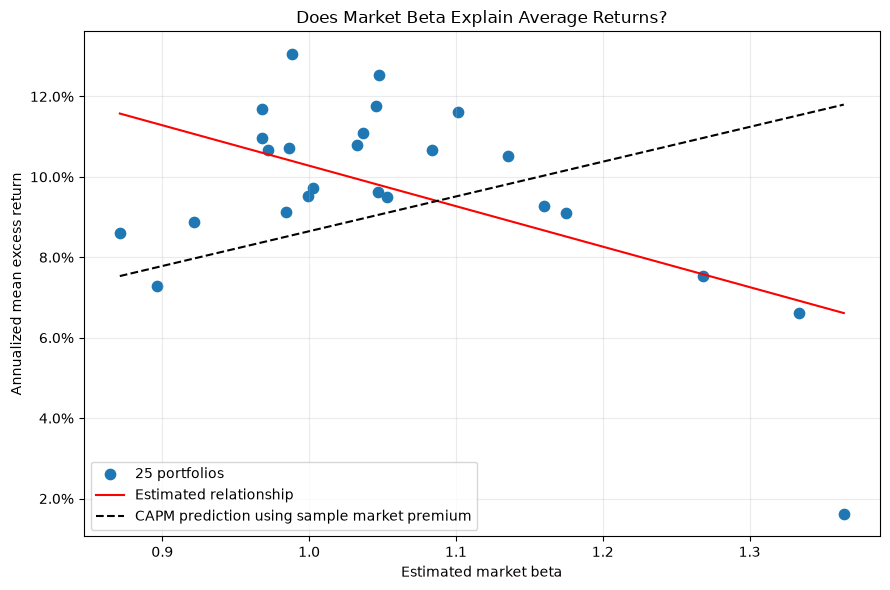

In [45]:
beta_grid = np.linspace(betas.min(), betas.max(), 100)

fig, ax = plt.subplots(figsize=(9, 6))

ax.scatter(
    betas,
    average_returns_annual,
    label="25 portfolios",
    s=55,
)

ax.plot(
    beta_grid,
    cross_model.params["const"]
    + cross_model.params["Beta"] * beta_grid,
    label="Estimated relationship",
    color="red",
)

ax.plot(
    beta_grid,
    market.mean() * 12 * beta_grid,
    label="CAPM prediction using sample market premium",
    color="black",
    linestyle="--",
)

ax.set_xlabel("Estimated market beta")
ax.set_ylabel("Annualized mean excess return")
ax.yaxis.set_major_formatter(PercentFormatter(1))
ax.set_title("Does Market Beta Explain Average Returns?")
ax.legend()
ax.grid(alpha=0.25)

plt.tight_layout()
plt.show()

### 4. Conclusion

Broadly speaking, do these results support DFA's belief in size and value portfolios containing premia unrelated to the market premium?

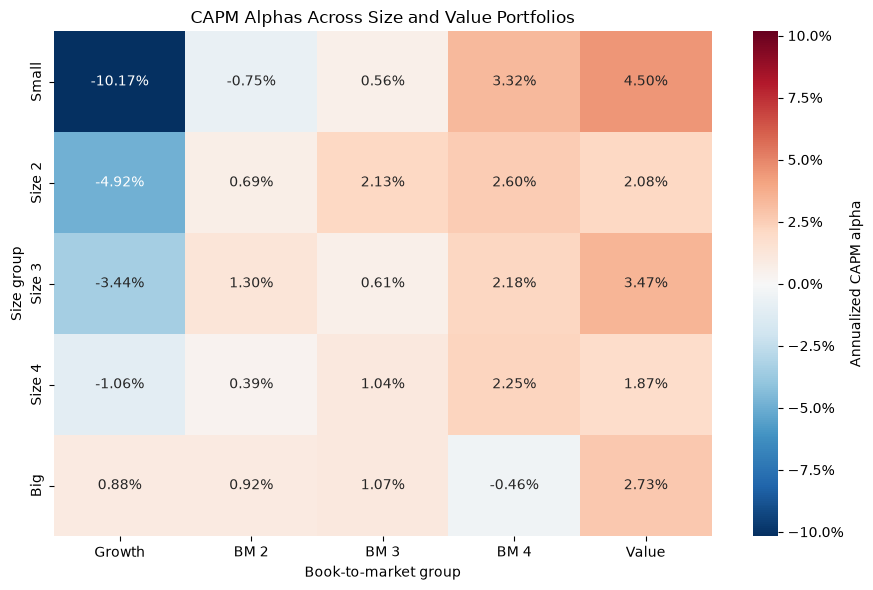

In [46]:
alpha_grid = pd.DataFrame(
    capm_results["Alpha (annual)"].to_numpy().reshape(5, 5),
    index=["Small", "Size 2", "Size 3", "Size 4", "Big"],
    columns=["Growth", "BM 2", "BM 3", "BM 4", "Value"],
)

limit = np.abs(alpha_grid.to_numpy()).max()

plt.figure(figsize=(9, 6))

sns.heatmap(
    alpha_grid,
    annot=True,
    fmt=".2%",
    cmap="RdBu_r",
    center=0,
    vmin=-limit,
    vmax=limit,
    cbar_kws={
        "label": "Annualized CAPM alpha",
        "format": PercentFormatter(1),
    },
)

plt.title("CAPM Alphas Across Size and Value Portfolios")
plt.xlabel("Book-to-market group")
plt.ylabel("Size group")
plt.tight_layout()
plt.show()

Here if the market explained everything, population alphas would be zero throughout the grid. Here we see large differences for example small-growth alpha is approximately −10.17% annually, while small-value alpha is approximately +4.50%.

Together with the 2.22% MAE and poor cross-sectional fit, this supports the argument that market beta alone misses systematic return differences. The evidence is particularly clear across growth and value portfolios. This does not prove that SMB and HML explain these differences just the market beta. 

### 5. Joint Test of Alphas

We measured how well the CAPM performs by checking the MAE of the time-series alphas.

Under classic statistical assumptions, we can test the null hypothesis that the CAPM works by calculating,

$$
H = T\left[1+\left(\text{SR}_{\text{mkt}}\right)^2\right]^{-1} \boldsymbol{\alpha}'\boldsymbol{\Sigma}_\epsilon^{-1}\boldsymbol{\alpha}
$$

This test statistic has a chi-squared distribution...

$$H\sim \chi^2_n$$

Note the following:

- $\boldsymbol{\alpha}$ is an $n\times 1$ vector of the individual regression alphas, $\alpha^i$.
- $\boldsymbol{\Sigma}_\epsilon$ is the $n\times n$ covariance matrix of the time-series of regression residuals, $\epsilon^i$, corresponding to each regression. 
- $\text{SR}_{\text{mkt}}$ is the monthly Sharpe ratio of $\tilde{r}^{\text{mkt}}$.

The test statistic, $H$, has a chi-squared distribution with $n=25$ degrees of freedom. So under the null hypothesis of the CAPM holding, $H$ should be small, and the distribution allows us to calculate the probability of seeing such a large $H$, conditional on the CAPM being true.

- Which is a stricter test: checking whether any of the $n$ values of $\alpha^i$ have a statistically significant t-test or checking whether $H$ calculated above is significant?

- Conceptually, how does the test-statistic $H$ relate to checking whether $\tilde{r}^{\text{mkt}}$ spans the tangency portfolio?

In [47]:
T, n = excess_returns.shape

alpha_monthly = capm_results["Alpha (monthly)"].to_numpy()

# Sample covariance of the 25 monthly residual series.
sigma_epsilon = residuals.cov().to_numpy()

market_sharpe_monthly = market.mean() / market.std(ddof=1)

# Solve Sigma * x = alpha rather than explicitly calculating an inverse.
weighted_alpha = np.linalg.solve(sigma_epsilon, alpha_monthly)

H = (
    T
    / (1 + market_sharpe_monthly**2)
    * (alpha_monthly @ weighted_alpha)
)

p_value = chi2.sf(H, df=n)
critical_value = chi2.ppf(0.95, df=n)

print(f"H statistic: {H:.3f}")
print(f"Degrees of freedom: {n}")
print(f"5% critical value: {critical_value:.3f}")
print(f"P-value: {p_value:.3e}")

if p_value < 0.05:
    print("Reject the null that all 25 CAPM alphas are zero.")
else:
    print("Do not reject the null that all 25 CAPM alphas are zero.")

H statistic: 131.523
Degrees of freedom: 25
5% critical value: 37.652
P-value: 1.961e-16
Reject the null that all 25 CAPM alphas are zero.


The joint test produces an H-statistic of approximately 131.52 and a p-value of 1.961e-16 so we reject the null hypothesis that all 25 CAPM alphas are zero. This provides strong evidence that market exposure alone does not fully explain these portfolios’ average excess returns. Unlike checking 25 separate, unadjusted t-tests, the joint test evaluates all alphas together while accounting for correlations among portfolio residuals.

# 4. Beyond CAPM

### 1.

Re-do the analysis of `3.2` and `3.3`, but instead of using the market return as the factor, use a new factor: the in-sample tangency portfolio of the $n=25$ portfolios. 

Use the portfolio excess returns from Section 3. The new factor is the tangency portfolio formed from these 25 portfolios.

- Calculate $\tilde{r}^{\text{tan}}$ by solving the MV optimization of the $n$ excess returns. 
- Consider this to be your single factor.

Instead of testing the CAPM, you will test the tangency-factor model:

$$
\mathbb{E}\left[\tilde{r}_{t}^{i}\right] = \beta^{i,\text{tan}}\; \mathbb{E}\left[\tilde{r}_{t}^{\text{tan}}\right]
$$

What do you find?

In [48]:
# Helper functions from ChatGPT 

def run_factor_model(asset_returns, model_factors):
    """Regress each portfolio's monthly excess returns on the factors."""
    assert asset_returns.index.equals(model_factors.index)

    X = sm.add_constant(model_factors)
    results = {}
    residuals = pd.DataFrame(index=asset_returns.index)

    for portfolio in asset_returns.columns:
        model = sm.OLS(asset_returns[portfolio], X).fit()

        alpha = model.params["const"]
        residual_vol = model.resid.std(ddof=1)

        results[portfolio] = {
            "Alpha (monthly)": alpha,
            "Alpha (annual)": alpha * 12,
            "Information ratio (annual)": (
                alpha / residual_vol * np.sqrt(12)
            ),
            "R-squared": model.rsquared,
        }

        for factor in model_factors.columns:
            results[portfolio][f"Beta: {factor}"] = model.params[factor]

        residuals[portfolio] = model.resid

    results = pd.DataFrame.from_dict(results, orient="index")
    results.index.name = "Portfolio"

    return results, residuals


def run_cross_section(asset_returns, time_series_results, model_factors):
    """Regress annualized portfolio means on their estimated factor betas."""
    beta_columns = [f"Beta: {f}" for f in model_factors.columns]

    betas = time_series_results[beta_columns].copy()
    betas.columns = model_factors.columns

    y = asset_returns.mean() * 12
    X = sm.add_constant(betas)
    model = sm.OLS(y, X).fit()

    estimates = pd.DataFrame({
        "Estimated annual coefficient": model.params,
        "Model-implied annual coefficient": pd.concat([
            pd.Series({"const": 0.0}),
            model_factors.mean() * 12,
        ]),
    })

    display(estimates.style.format("{:.2%}"))
    print(f"Cross-sectional R-squared: {model.rsquared:.4f}")

    return model


def show_factor_results(results):
    visible = results.drop(columns="Alpha (monthly)")
    formatting = {column: "{:.3f}" for column in visible.columns}
    formatting["Alpha (annual)"] = "{:.2%}"

    display(visible.style.format(formatting))

    mae = results["Alpha (annual)"].abs().mean()
    print(f"Annualized MAE: {mae:.6%}")

In [49]:
# Estimate monthly means and covariance from the 25 portfolios.
mu = excess_returns.mean()
sigma = excess_returns.cov()

unnormalized_weights = np.linalg.solve(
    sigma.to_numpy(),
    mu.to_numpy()
)

weight_sum = unnormalized_weights.sum()
if np.isclose(weight_sum, 0):
    raise ValueError("Tangency weights cannot be normalized to sum to one.")

tangency_weights = pd.Series(
    unnormalized_weights / weight_sum,
    index=excess_returns.columns,
    name="Tangency weight",
)

tangency_returns = excess_returns @ tangency_weights

tangency_factors = tangency_returns.to_frame(name="Tangency")

display(tangency_weights.to_frame().style.format("{:.2%}"))
print(f"Sum of weights: {tangency_weights.sum():.4f}")

display(
    performance_stats(tangency_factors).style.format(formats)
)

,Tangency weight
SMALL LoBM,-194.56%
ME1 BM2,59.46%
ME1 BM3,26.86%
ME1 BM4,91.23%
SMALL HiBM,101.04%
ME2 BM1,-46.16%
ME2 BM2,86.58%
ME2 BM3,39.66%
ME2 BM4,-14.67%
ME2 BM5,-78.70%


Sum of weights: 1.0000


,Annualized mean,Annualized volatility,Annualized Sharpe,Monthly VaR (5%)
Tangency,36.10%,20.10%,1.796,-6.77%


In [50]:
tangency_results, tangency_residuals = run_factor_model(
    excess_returns,
    tangency_factors,
)

# Single-factor Treynor ratio: mean excess return divided by factor beta.
tangency_results["Treynor (annual)"] = (
    excess_returns.mean() * 12
    / tangency_results["Beta: Tangency"]
)

show_factor_results(tangency_results)

print(
    "Annualized tangency-factor mean: "
    f"{tangency_returns.mean() * 12:.2%}"
)

,Alpha (annual),Information ratio (annual),R-squared,Beta: Tangency,Treynor (annual)
Portfolio,,,,,
SMALL LoBM,0.00%,0.000,0.001,0.045,0.361
ME1 BM2,0.00%,0.000,0.049,0.257,0.361
ME1 BM3,0.00%,0.000,0.071,0.266,0.361
ME1 BM4,0.00%,0.000,0.114,0.324,0.361
SMALL HiBM,0.00%,0.000,0.124,0.361,0.361
ME2 BM1,0.00%,0.000,0.023,0.183,0.361
ME2 BM2,0.00%,0.000,0.082,0.291,0.361
ME2 BM3,0.00%,0.000,0.110,0.307,0.361
ME2 BM4,0.00%,0.000,0.114,0.304,0.361


Annualized MAE: 0.000000%
Annualized tangency-factor mean: 36.10%


In [51]:
tangency_cross_model = run_cross_section(
    excess_returns,
    tangency_results,
    tangency_factors,
)

,Estimated annual coefficient,Model-implied annual coefficient
const,0.00%,0.00%
Tangency,36.10%,36.10%


Cross-sectional R-squared: 1.0000


### 2.

Re-do the analysis of `3.2` and `3.3`, but instead of using only the `Mkt-RF` factor, use `Mkt-RF`, `SMB`, and `HML`. 

Use the portfolio excess returns from Section 3. All three factors are already excess returns; do not subtract `RF` from them.

Thus, instead of testing the CAPM, you will be testing the Fama-French 3-Factor Model.

$$
\mathbb{E}\left[\tilde{r}_{t}^{i}\right] = \beta^{i,\text{mkt}}\; \mathbb{E}\left[\tilde{r}_{t}^{\text{mkt}}\right] + \beta^{i,\text{size}}\; \mathbb{E}\left[\tilde{r}_{t}^{\text{size}}\right] + \beta^{i,\text{val}}\; \mathbb{E}\left[\tilde{r}_{t}^{\text{val}}\right]
$$

In [52]:
ff3_factors = factor_data[["Mkt-RF", "SMB", "HML"]].copy()

assert ff3_factors.index.equals(excess_returns.index)

ff3_results, ff3_residuals = run_factor_model(
    excess_returns,
    ff3_factors,
)

show_factor_results(ff3_results)

,Alpha (annual),Information ratio (annual),R-squared,Beta: Mkt-RF,Beta: SMB,Beta: HML
Portfolio,,,,,,
SMALL LoBM,-7.69%,-0.832,0.884,1.124,1.374,-0.257
ME1 BM2,0.57%,0.080,0.906,0.962,1.331,-0.010
ME1 BM3,0.33%,0.063,0.931,0.931,1.063,0.277
ME1 BM4,2.18%,0.457,0.939,0.879,1.075,0.481
SMALL HiBM,2.41%,0.332,0.877,0.932,1.055,0.690
ME2 BM1,-2.49%,-0.407,0.937,1.133,1.055,-0.314
ME2 BM2,1.06%,0.204,0.935,1.015,0.933,0.117
ME2 BM3,1.06%,0.196,0.916,0.986,0.732,0.394
ME2 BM4,0.69%,0.153,0.938,0.939,0.769,0.588


Annualized MAE: 1.383081%


In [53]:
ff3_results["Market-beta Treynor (annual)"] = (
    excess_returns.mean() * 12
    / ff3_results["Beta: Mkt-RF"]
)

display(
    ff3_results[["Market-beta Treynor (annual)"]]
    .style.format("{:.2%}")
)

,Market-beta Treynor (annual)
Portfolio,
SMALL LoBM,1.45%
ME1 BM2,9.64%
ME1 BM3,10.33%
ME1 BM4,13.29%
SMALL HiBM,13.99%
ME2 BM1,5.84%
ME2 BM2,10.36%
ME2 BM3,11.26%
ME2 BM4,11.68%


In [54]:
ff3_cross_model = run_cross_section(
    excess_returns,
    ff3_results,
    ff3_factors,
)

,Estimated annual coefficient,Model-implied annual coefficient
const,16.75%,0.00%
Mkt-RF,-7.91%,8.65%
SMB,-0.13%,0.31%
HML,3.53%,3.26%


Cross-sectional R-squared: 0.4762


In [55]:
capm_comparison, _ = run_factor_model(
    excess_returns,
    factor_data[["Mkt-RF"]],
)

comparison = pd.DataFrame({
    "CAPM": {
        "Annualized MAE":
            capm_comparison["Alpha (annual)"].abs().mean(),
        "Average time-series R-squared":
            capm_comparison["R-squared"].mean(),
    },
    "Tangency factor": {
        "Annualized MAE":
            tangency_results["Alpha (annual)"].abs().mean(),
        "Average time-series R-squared":
            tangency_results["R-squared"].mean(),
    },
    "Fama–French 3-factor": {
        "Annualized MAE":
            ff3_results["Alpha (annual)"].abs().mean(),
        "Average time-series R-squared":
            ff3_results["R-squared"].mean(),
    },
}).T

display(
    comparison.style.format({
        "Annualized MAE": "{:.4%}",
        "Average time-series R-squared": "{:.3f}",
    })
)

,Annualized MAE,Average time-series R-squared
CAPM,2.2160%,0.718
Tangency factor,0.0000%,0.086
Fama–French 3-factor,1.3831%,0.902
